In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df.isna().sum().sum()

np.int64(0)

In [9]:
df["TotalCharges"].value_counts().head(10)

TotalCharges
20.2     11
         11
19.75     9
19.65     8
19.9      8
20.05     8
19.55     7
45.3      7
19.45     6
20.25     6
Name: count, dtype: int64

In [10]:
df["TotalCharges"].dtype

dtype('O')

In [11]:
pd.to_numeric(df["TotalCharges"], errors="coerce").isna().sum()

np.int64(11)

In [12]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [13]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [14]:
df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [15]:
df = df.dropna(subset=["TotalCharges"])

In [16]:
df.shape

(7032, 21)

In [17]:
df["TotalCharges"].isnull().sum()

np.int64(0)

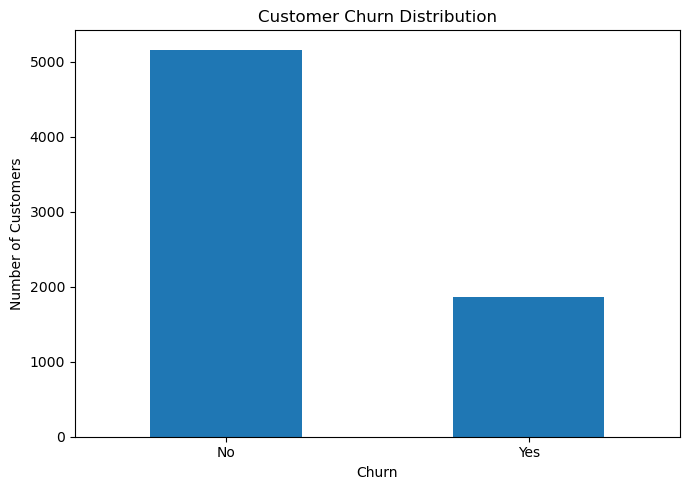

In [19]:
import matplotlib.pyplot as plt

churn_counts = df["Churn"].value_counts()

plt.figure(figsize=(7, 5))
churn_counts.plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../reports/churn_distribution.png", dpi=300)
plt.show()

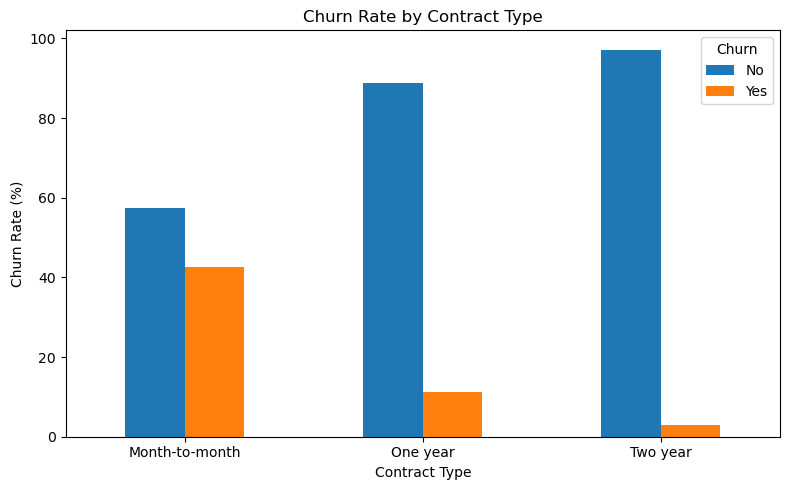

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()

plt.savefig("../reports/churn_by_contract.png", dpi=300)
plt.show()

In [21]:
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"],
    include_lowest=True
)

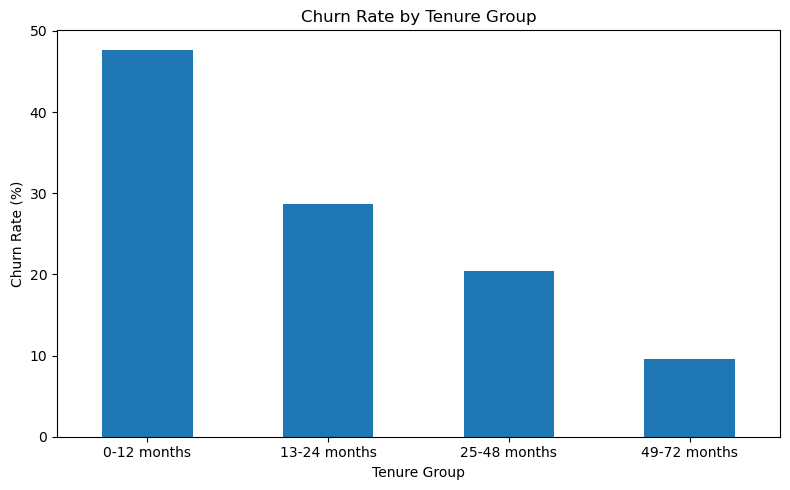

In [22]:
tenure_churn = pd.crosstab(
    df["tenure_group"],
    df["Churn"],
    normalize="index"
) * 100

tenure_churn["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../reports/churn_by_tenure.png", dpi=300)
plt.show()

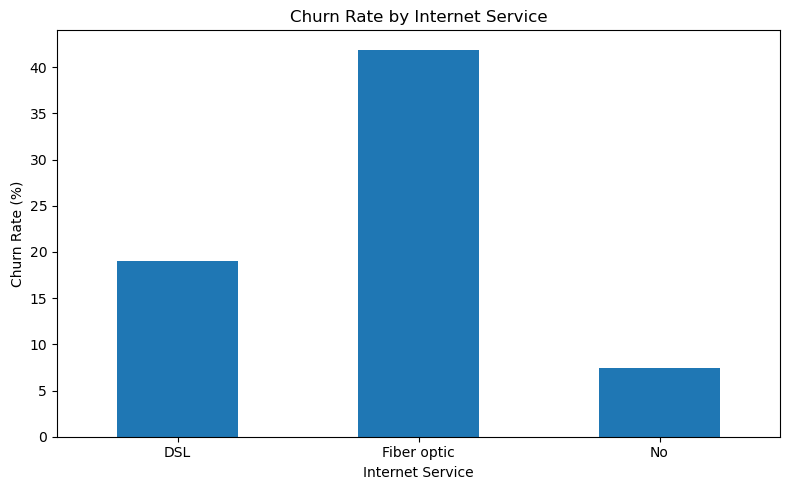

In [23]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

internet_churn["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../reports/churn_by_internet_service.png", dpi=300)
plt.show()

In [24]:
print("Overall Churn Rate:")
print(df["Churn"].value_counts(normalize=True) * 100)

print("\nChurn Rate by Contract:")
print(
    pd.crosstab(
        df["Contract"],
        df["Churn"],
        normalize="index"
    )["Yes"] * 100
)

print("\nChurn Rate by Tenure Group:")
print(
    pd.crosstab(
        df["tenure_group"],
        df["Churn"],
        normalize="index"
    )["Yes"] * 100
)

print("\nChurn Rate by Internet Service:")
print(
    pd.crosstab(
        df["InternetService"],
        df["Churn"],
        normalize="index"
    )["Yes"] * 100
)

print("\nAverage Monthly Charges by Churn:")
print(df.groupby("Churn")["MonthlyCharges"].mean())

Overall Churn Rate:
Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64

Churn Rate by Contract:
Contract
Month-to-month    42.709677
One year          11.277174
Two year           2.848665
Name: Yes, dtype: float64

Churn Rate by Tenure Group:
tenure_group
0-12 months     47.678161
13-24 months    28.710938
25-48 months    20.388959
49-72 months     9.513176
Name: Yes, dtype: float64

Churn Rate by Internet Service:
InternetService
DSL            18.998344
Fiber optic    41.892765
No              7.434211
Name: Yes, dtype: float64

Average Monthly Charges by Churn:
Churn
No     61.307408
Yes    74.441332
Name: MonthlyCharges, dtype: float64


## 5 Business Insights

1. **Overall Churn:** Approximately **26.58%** of customers have churned, indicating that customer retention is an important business concern.

2. **Contract Type:** Customers with **month-to-month contracts** have the highest churn rate at approximately **42.71%**, while one-year contracts have **11.28%** and two-year contracts only **2.85%** churn.

3. **Customer Tenure:** Customers with **0-12 months of tenure** have the highest churn rate at approximately **47.68%**. Churn decreases as customer tenure increases, reaching only **9.51%** for customers with 49-72 months of tenure.

4. **Internet Service:** Customers using **Fiber optic** service have a high churn rate of approximately **41.89%**, compared with approximately **19.00%** for DSL customers.

5. **Monthly Charges:** Customers who churned had an average monthly charge of approximately **₹74.44**, compared with approximately **₹61.31** for customers who did not churn. This suggests that higher monthly charges may be associated with increased churn.